# 08. Улучшение модели 2026: новые признаки, вес свежих вакансий, смесь с LightGBM

Отправная точка: модель F из ноутбука 07, MAE 26 693 сом на вакансиях июля–октября 2026.

**Идеи, которые проверяются:**
1. **Формат вакансии из поля «Тип»** в постах codifynews: office / remote / internship / project / «можно удалённо…».
   Раньше из него бралась только отметка «удалённо».
2. **Поле «Дополнительно»** (опыт, город, иногда стек) как текст.
3. **Сила регуляризации** Ridge (alpha) заново, потому что параметры подбирались на данных 2024 года.
4. **Вес свежих вакансий:** вакансия месячной давности важнее вакансии двухлетней давности
   (вес = 0,5 в степени «возраст / период полураспада»).
5. **Смесь с LightGBM:** градиентный бустинг на средних зарплатах заголовка, работодателя и профессии
   (target encoding, считается без подглядывания: для каждой строки обучения по другим фолдам).

**Честный подбор:** настройки выбираются на **валидации** (обучение до апреля 2026, проверка на апреле–июне),
а тест (июль–октябрь) открывается **один раз** в конце.

In [1]:
import sys, json, time, warnings
warnings.filterwarnings("ignore", category=UserWarning)
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
import prep, blend

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")

df, d = blend.load_2026()
P = json.load(open("../models/final_model_meta.json"))["params"]
VAL_FROM, TEST_FROM = pd.Timestamp("2026-04-01"), pd.Timestamp("2026-07-01")
tr_v, val = blend.time_split(d, VAL_FROM, TEST_FROM)    # для подбора настроек
tr_t, test = blend.time_split(d, TEST_FROM)             # для итоговой проверки
print(f"валидация: обучение {len(tr_v)}, проверка {len(val)} | тест: обучение {len(tr_t)}, проверка {len(test)}")
print("Формат вакансии (поле «Тип»), codifynews:")
d.loc[d["source"] == "telegram_codifynews", "fmt"].value_counts().head(8)

/home/claude/kg-salary-prediction/notebooks/../src/prep.py:41: DtypeWarning: Columns (0: skills, 1: requirements, 2: responsibilities) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


Вакансий: 41302 | с зарплатой после очистки: 22563 (шум 29, повторы 118)
валидация: обучение 18567, проверка 1494 | тест: обучение 20389, проверка 1784
Формат вакансии (поле «Тип»), codifynews:


fmt
полная занятость       9220
office                 5181
remote                 1085
можно удаленно          517
не указан               216
частичная занятость      98
project                  60
relocate                 53
Name: count, dtype: int64

### Насколько формат вакансии связан с зарплатой (codifynews 2025–2026)

In [2]:
c = d[(d["source"] == "telegram_codifynews") & (d["published"] >= "2025-01-01")]
f = c.groupby("fmt")["salary_kgs"].agg(вакансий="size", медиана="median")
f[f["вакансий"] >= 50].sort_values("медиана", ascending=False).style.format({"медиана": "{:,.0f}"})

,вакансий,медиана
fmt,,
можно удаленно,273,"240,488"
false,53,"218,625"
remote,585,"109,312"
office,3181,"80,000"
не указан,72,"70,000"
полная занятость,6811,"60,000"


## 1. Подбор настроек на валидации

Ridge с новыми признаками: alpha × период полураспада веса. Затем доля LightGBM в смеси.

In [3]:
def ridge_only(alpha, hl):
    return blend.BlendModel(P, alpha=alpha, half_life=hl, w_gbm=0)

grid = []
for alpha in [P["alpha"], 5, 10]:
    for hl in [None, 6, 12, 24]:
        m = ridge_only(alpha, hl).fit(tr_v)
        mm = prep.metrics(val["y"].values, m.predict(val))
        grid.append({"alpha": round(alpha, 2), "полураспад, мес": hl or "без веса", "MAE валидации": mm["MAE, сом"],
                     "медианная ошибка": mm["медианная ошибка, сом"]})
grid = pd.DataFrame(grid)
best_r = grid.loc[grid["MAE валидации"].idxmin()]
ALPHA = float(best_r["alpha"]); HL = None if best_r["полураспад, мес"] == "без веса" else int(best_r["полураспад, мес"])
print(f"Лучшее на валидации: alpha = {ALPHA}, полураспад = {HL}")
grid.pivot(index="alpha", columns="полураспад, мес", values="MAE валидации").style.format("{:,.0f}").highlight_min(axis=None, color="#cde8cd")

Лучшее на валидации: alpha = 2.62, полураспад = 6


"полураспад, мес",6,12,24,без веса
alpha,,,,
2.620000,"24,571","24,688","24,835","25,082"
5.000000,"24,768","24,747","24,814","24,970"
10.000000,"25,172","25,069","25,060","25,086"


Лучшая доля LightGBM на валидации: 0.3


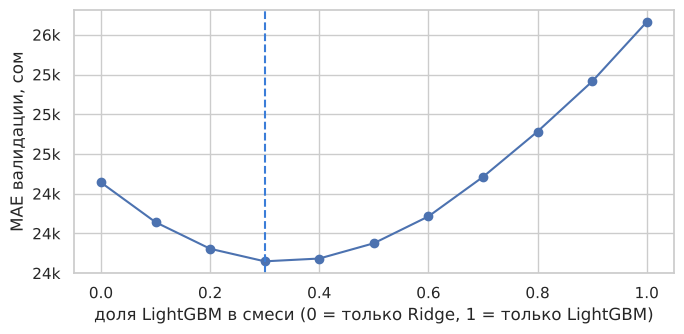

In [4]:
m = blend.BlendModel(P, alpha=ALPHA, half_life=HL, w_gbm=0.5).fit(tr_v)
r, g = m.predict_parts(val)
ws = np.round(np.arange(0, 1.01, 0.1), 1)
bw = pd.DataFrame({"доля LightGBM": ws,
                   "MAE валидации": [prep.metrics(val["y"].values, w * g + (1 - w) * r)["MAE, сом"] for w in ws]})
W = float(bw.loc[bw["MAE валидации"].idxmin(), "доля LightGBM"])
print(f"Лучшая доля LightGBM на валидации: {W}")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(bw["доля LightGBM"], bw["MAE валидации"], marker="o"); ax.axvline(W, color="#3b7dd8", ls="--")
ax.set_xlabel("доля LightGBM в смеси (0 = только Ridge, 1 = только LightGBM)"); ax.set_ylabel("MAE валидации, сом")
ax.yaxis.set_major_formatter(K); plt.tight_layout(); plt.show()

## 2. Итог на тесте: вклад каждого шага

Каждая строка добавляет к предыдущей одно изменение. Все модели обучены на данных до июля 2026
и проверены на одних и тех же вакансиях июля–октября.

In [5]:
def ridge_custom(cat, text, alpha, hl):
    p = P
    ct = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=p["min_freq"]), cat),
        ("num", StandardScaler(), blend.RIDGE_NUM),
        ("t", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, ngram_range=(1, p["word_ngram"]), max_features=p["word_max"]), text),
        ("ti", TfidfVectorizer(min_df=p["min_df"], sublinear_tf=True, analyzer="char_wb", ngram_range=(2, p["char_max"])), "title"),
    ], transformer_weights={"ti": p["title_weight"]})
    m = make_pipeline(ct, Ridge(alpha=alpha))
    return m.fit(tr_t, tr_t["y"], ridge__sample_weight=blend.recency_weight(tr_t, hl))

F_CAT = [c for c in blend.RIDGE_CAT if c != "fmt"]
steps = {
    "F из ноутбука 07":                         ridge_custom(F_CAT, "full", P["alpha"], None),
    "+ формат вакансии («Тип»)":               ridge_custom(blend.RIDGE_CAT, "full", P["alpha"], None),
    "+ «Тип» и «Дополнительно» в тексте":      ridge_custom(blend.RIDGE_CAT, "full2", P["alpha"], None),
    f"+ alpha {ALPHA:g} и вес свежести ({HL} мес)": ridge_custom(blend.RIDGE_CAT, "full2", ALPHA, HL),
}
preds, rows = {}, []
for name, m in steps.items():
    preds[name] = m.predict(test)
final_t = blend.BlendModel(P, alpha=ALPHA, half_life=HL, w_gbm=W).fit(tr_t)
preds[f"+ смесь с LightGBM (доля {W:g})"] = final_t.predict(test)
for name, p in preds.items():
    mm = prep.metrics(test["y"].values, p)
    rows.append({"шаг": name, **mm, "смещение, %": (np.exp(p) / test["salary_kgs"] - 1).median() * 100})
steps_tab = pd.DataFrame(rows).set_index("шаг")
steps_tab["изменение MAE"] = steps_tab["MAE, сом"] / steps_tab["MAE, сом"].iloc[0] - 1
steps_tab.style.format({"MAE, сом": "{:,.0f}", "медианная ошибка, сом": "{:,.0f}", "MAPE, %": "{:.1f}",
                        "доля ошибок < 20%": "{:.0%}", "R² (log)": "{:.3f}", "смещение, %": "{:+.1f}", "изменение MAE": "{:+.1%}"})

,"MAE, сом","медианная ошибка, сом","MAPE, %",доля ошибок < 20%,R² (log),"смещение, %",изменение MAE
шаг,,,,,,,
F из ноутбука 07,"26,693","16,541",35.2,41%,0.374,+1.1,+0.0%
+ формат вакансии («Тип»),"26,419","16,482",34.2,41%,0.391,+0.3,-1.0%
+ «Тип» и «Дополнительно» в тексте,"26,218","16,391",34.0,41%,0.396,+0.1,-1.8%
+ alpha 2.62 и вес свежести (6 мес),"25,745","16,155",33.8,42%,0.404,+0.4,-3.6%
+ смесь с LightGBM (доля 0.3),"25,191","15,268",32.6,44%,0.420,-1.4,-5.6%


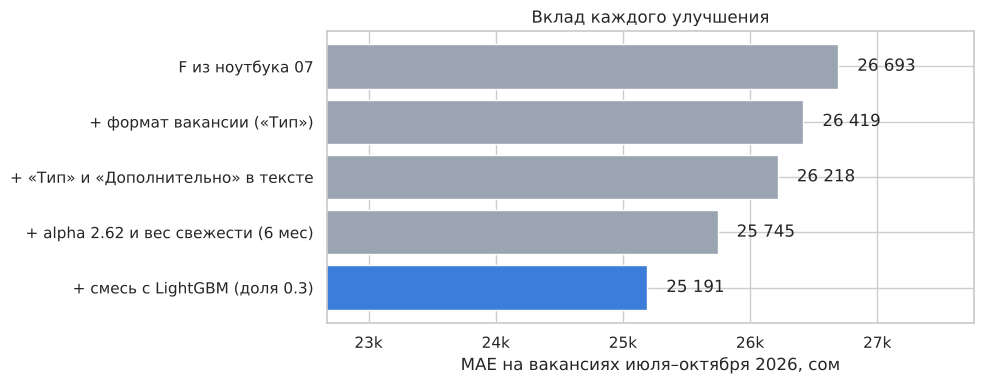

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
v = steps_tab["MAE, сом"]
ax.barh(v.index[::-1], v.values[::-1], color=["#3b7dd8"] + ["#9aa5b1"] * (len(v) - 1))
for i, x in enumerate(v.values[::-1]):
    ax.text(x + 150, i, f"{x:,.0f}".replace(",", " "), va="center")
ax.set_xlim(v.min() * 0.9, v.max() * 1.04); ax.xaxis.set_major_formatter(K)
ax.set_xlabel("MAE на вакансиях июля–октября 2026, сом"); ax.set_title("Вклад каждого улучшения")
plt.tight_layout(); plt.savefig(FIG + "08_steps.png", dpi=150); plt.show()

### По сегментам: модель F против улучшенной

In [7]:
t = test.assign(F=np.exp(preds["F из ноутбука 07"]), new=np.exp(preds[list(preds)[-1]]))
t["band"] = pd.cut(t["salary_kgs"], [0, 25e3, 40e3, 60e3, 100e3, 1e9], labels=["<25k", "25–40k", "40–60k", "60–100k", "100k+"])
def seg(g):
    return pd.Series({"вакансий": len(g), "MAE F": (g["F"] - g["salary_kgs"]).abs().mean(),
                      "MAE новая": (g["new"] - g["salary_kgs"]).abs().mean(),
                      "медианная ошибка новой": (g["new"] - g["salary_kgs"]).abs().median()})
seg_tab = pd.concat([t.groupby("source").apply(seg), t.groupby("band", observed=True).apply(seg),
                     t[t["category"] == "Информационные технологии"].pipe(seg).to_frame("IT").T, seg(t).to_frame("весь тест").T])
seg_tab["изменение"] = seg_tab["MAE новая"] / seg_tab["MAE F"] - 1
seg_tab.style.format({"вакансий": "{:.0f}", "MAE F": "{:,.0f}", "MAE новая": "{:,.0f}", "медианная ошибка новой": "{:,.0f}", "изменение": "{:+.0%}"})

,вакансий,MAE F,MAE новая,медианная ошибка новой,изменение
telegram_codifynews,1404,"28,945","27,807","17,305",-4%
telegram_kgworkzone,380,"18,371","15,526","9,972",-15%
<25k,54,"26,999","28,277","22,922",+5%
25–40k,272,"18,619","17,156","13,222",-8%
40–60k,495,"14,354","12,415","9,356",-14%
60–100k,617,"18,430","15,727","13,020",-15%
100k+,346,"65,381","66,180","49,753",+1%
IT,267,"36,123","32,220","19,778",-11%
весь тест,1784,"26,693","25,191","15,268",-6%


### Уровень профессии: медиана прогноза против реальной медианы теста

In [8]:
pp = t.groupby("sub_category").agg(вакансий=("salary_kgs", "size"), реальная=("salary_kgs", "median"),
                                    F=("F", "median"), новая=("new", "median"))
pp = pp[pp["вакансий"] >= 20].sort_values("вакансий", ascending=False)
pp["ошибка F"] = (pp["F"] / pp["реальная"] - 1).abs(); pp["ошибка новой"] = (pp["новая"] / pp["реальная"] - 1).abs()
print(f"Медианная ошибка по профессиям: F {pp['ошибка F'].median():.1%}, новая {pp['ошибка новой'].median():.1%}")
pp.style.format({"реальная": "{:,.0f}", "F": "{:,.0f}", "новая": "{:,.0f}", "ошибка F": "{:.0%}", "ошибка новой": "{:.0%}"})

Медианная ошибка по профессиям: F 4.1%, новая 3.9%


,вакансий,реальная,F,новая,ошибка F,ошибка новой
sub_category,,,,,,
"Менеджер по продажам, менеджер по работе с клиентами",508,"70,000","67,995","71,450",3%,2%
Другое,162,"70,000","67,327","65,145",4%,7%
"Программист, разработчик",150,"100,000","110,198","98,190",10%,2%
"SMM-менеджер, контент-менеджер",115,"45,000","42,775","43,263",5%,4%
"Менеджер по маркетингу, интернет-маркетолог",73,"69,960","69,517","68,671",1%,2%
"Продавец-консультант, продавец-кассир",58,"46,500","50,616","46,319",9%,0%
"Дизайнер, художник",41,"80,000","76,579","69,444",4%,13%
"Повар, пекарь, кондитер",36,"60,000","52,304","53,469",13%,11%
Системный администратор,35,"55,000","66,719","63,116",21%,15%


## 3. Диапазоны для новой модели

Ошибки считаются на валидации (модель обучена до апреля 2026), покрытие проверяется на тесте.

In [9]:
m_val = blend.BlendModel(P, alpha=ALPHA, half_life=HL, w_gbm=W).fit(tr_v)
resid = val["y"].values - m_val.predict(val)
Q = {}
for src in sorted(d["source"].unique()):
    r = resid[(val["source"] == src).values] if (val["source"] == src).sum() >= 100 else resid
    Q[src] = {"50%": np.quantile(r, [.25, .75]).tolist(), "80%": np.quantile(r, [.1, .9]).tolist()}
p = preds[list(preds)[-1]]
cov = []
for lvl in ["50%", "80%"]:
    lo = np.array([Q[s][lvl][0] for s in test["source"]]); hi = np.array([Q[s][lvl][1] for s in test["source"]])
    inside = (test["y"].values >= p + lo) & (test["y"].values <= p + hi)
    cov.append({"уровень": lvl, "покрытие на тесте": inside.mean(),
                "диапазон (codifynews)": f"×{np.exp(Q['telegram_codifynews'][lvl][0]):.2f} … ×{np.exp(Q['telegram_codifynews'][lvl][1]):.2f}",
                "диапазон (kgworkzone)": f"×{np.exp(Q['telegram_kgworkzone'][lvl][0]):.2f} … ×{np.exp(Q['telegram_kgworkzone'][lvl][1]):.2f}"})
pd.DataFrame(cov).style.format({"покрытие на тесте": "{:.0%}"}).hide(axis="index")

уровень,покрытие на тесте,диапазон (codifynews),диапазон (kgworkzone)
50%,51%,×0.75 … ×1.27,×0.87 … ×1.22
80%,80%,×0.56 … ×1.63,×0.69 … ×1.46


## 4. Финальная модель

Обучается на **всех** вакансиях 2024–2026 с выбранными настройками и заменяет `models/model_2026.joblib`.

In [10]:
final = blend.BlendModel(P, alpha=ALPHA, half_life=HL, w_gbm=W).fit(d)
joblib.dump(final, "../models/model_2026.joblib", compress=3)
last = steps_tab.iloc[-1]
meta = {"variant": "08: Ridge + LightGBM", "params": P, "alpha": ALPHA, "half_life": HL, "w_gbm": W,
        "trained_on": int(len(d)), "period": [str(d["published"].min().date()), str(d["published"].max().date())],
        "month_n_now": int(df["month_n"].max()), "interval_log_quantiles": Q,
        "test": {k: float(last[k]) for k in ["MAE, сом", "медианная ошибка, сом", "MAPE, %", "R² (log)"]}}
json.dump(meta, open("../models/model_2026_meta.json", "w"), ensure_ascii=False, indent=1)
print(f"Сохранено: models/model_2026.joblib, обучено на {len(d)} вакансиях")

Сохранено: models/model_2026.joblib, обучено на 22563 вакансиях


In [11]:
from predict import Predictor
pr = Predictor()
ex = pd.DataFrame([
    pr.predict("Менеджер по продажам", 1),
    pr.predict("Frontend разработчик", 1),
    pr.predict("Frontend разработчик", 3),
    pr.predict("Frontend разработчик", 3, job_type="remote"),
    pr.predict("Senior Frontend разработчик", 3),
    pr.predict("SMM-менеджер", 1),
    pr.predict("Официант", 0, source="telegram_kgworkzone"),
])
ex.style.format({"прогноз": "{:,.0f}"}).hide(axis="index")

вакансия,профессия,похожий заголовок,"опыт, лет",уровень,прогноз,50%,80%
Менеджер по продажам,"Менеджер по продажам, менеджер по работе с клиентами",менеджер по продажам,1,middle,"67,000","(50000, 85000)","(37000, 109000)"
Frontend разработчик,"Программист, разработчик",frontend разработчик,1,middle,"69,000","(51000, 87000)","(38000, 112000)"
Frontend разработчик,"Программист, разработчик",frontend разработчик,3,senior,"102,000","(76000, 130000)","(57000, 167000)"
Frontend разработчик,"Программист, разработчик",frontend разработчик,3,senior,"132,000","(99000, 168000)","(74000, 216000)"
Senior Frontend разработчик,"Программист, разработчик",senior frontend разработчик,3,senior,"130,000","(97000, 166000)","(73000, 213000)"
SMM-менеджер,"SMM-менеджер, контент-менеджер",smm-менеджер,1,middle,"38,000","(28000, 48000)","(21000, 62000)"
Официант,"Официант, бармен, бариста",официант,0,junior,"36,000","(31000, 44000)","(25000, 53000)"


## Выводы

1. **Ошибка снизилась на 5,6%:** MAE на вакансиях июля–октября 2026 с 26 693 до **25 191 сом**,
   медианная ошибка с 16 541 до **15 268 сом** (−8%), доля прогнозов с ошибкой меньше 20% с 41% до 44%.
   Настройки выбраны на валидации (апрель–июнь), тест открыт один раз.
2. **Что дало больше всего:**
   - формат вакансии и поле «Дополнительно»: −1,8%. Вакансии «можно удалённо» в codifynews стоят
     в 3 раза больше обычных «полная занятость» (240 тыс. против 60 тыс.);
   - больший вес свежих вакансий (полураспад 6 месяцев): ещё −1,8%. Цены 2024 года устаревают;
   - смесь с LightGBM (30% LightGBM, 70% Ridge): ещё −2,1%. Бустинг лучше использует среднюю зарплату
     конкретного работодателя и заголовка.
3. **Где выигрыш:** сфера услуг (kgworkzone) −15%, зарплаты 40–100 тыс. −14–15%, IT −11%.
   Крайние зарплаты (меньше 25 тыс. и больше 100 тыс.) не улучшились: это предел данных.
4. **По профессиям** медиана прогноза отличается от реальной медианы теста в среднем на **3,9%**
   (у модели F 4,1%); программисты: 98 тыс. против реальных 100 тыс.
5. **Диапазоны остались честными и стали уже:** 80% диапазон накрыл 80% тестовых вакансий,
   для codifynews ×0,56 … ×1,63 (было ×0,56 … ×1,72).
6. **Цена улучшения:** смесь осторожнее в крайних случаях. Например, «Senior Frontend разработчик»
   получает 130 тыс., хотя реальные Senior-вакансии стоят 200–300 тыс.: модель тянет редкие дорогие
   вакансии к середине.

**Финальная модель** (`models/model_2026.joblib`): Ridge + LightGBM, обучена на всех 22 563 вакансиях 2024–2026.